# 19 — Unfolding the total-mass distribution of detected binaries (matrix inversion, IBU, OmniFold)

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 49 (the course's unfolding module, L19-20). The IMR bank gives a *reconstructed* total mass M̂ (the best of 8 template masses) for every detected signal; the distribution of M̂ is a smeared, sculpted (detection efficiency depends on mass and SNR) version of the true distribution of M. Here the true distribution is recovered with

* **matrix inversion** of the response matrix,
* **iterative Bayesian unfolding** (IBU, D'Agostini) with 1–10 iterations, including the efficiency,
* **OmniFold** (unbinned, classifier-based iterative reweighting, Andreassen et al.) with gradient-boosted classifiers on reco features (M̂, q̂, ρ², lag) and truth features (M, q).

The response is built from a *simulation* with the training IMR library, a uniform mass prior and SNR ∝ ρ⁻⁴ (ρ = 6–40); the *pseudo-data* come from the held-out library with a very different mass distribution (a peak at 45 M☉ plus a tail) and different noise windows (test chunks), so the true answer is known. Selection: IMR-bank statistic above the FAP 10⁻² threshold of the validation noise. Uncertainties: bootstrap of the pseudo-data (30 replicas).

**What it does not do.** It unfolds a population *for this detector, this window and this SNR law*, not the astrophysical mass function; the mass reconstruction is coarse (8 template masses); only M (with q as an accompanying variable) is unfolded; one pseudo-data sample, so the comparison of methods has the scatter of that sample (shown by the bootstrap).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
import imr_tools as it
import gwosc_tools as g
g.style()
rng = np.random.default_rng(19)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
IB = {i: it.IMRBank(CH[i]["S1"]) for i in CH}
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1 = {sp: np.stack([CH[i]["S1"] for i in ID[sp]]) for sp in V}
LIB = {"imr": g.imr_library("train"), "imr_test": g.imr_library("test")}
EDGES = np.array([30, 38, 46, 55, 65, 75, 87, 100.0]); NB_ = len(EDGES) - 1
def scan(v, cid): o = g.scan_mixed(v, cid, IB); return np.column_stack([o["f0"], o["Q"], np.log(o["rho2"]), o["tau"]]), o["rho2"]
_, bk = scan(V["val"], ID["val"]); THR = g.threshold_at_far(bk, 1e-2); print("IMR-bank threshold (FAP 1e-2, validation):", round(THR, 1))

IMR-bank threshold (FAP 1e-2, validation): 28.4


## 1. Simulation (response) and pseudo-data

In [2]:
def simulate(kind, split, n, mass_weight=None, seed=0):
    r = np.random.default_rng(seed); lib = LIB[kind]
    p = g.draw_params(kind, r, n)
    if mass_weight is not None:
        w = mass_weight(lib["mtot"]); idx = r.choice(len(w), n, p=w / w.sum()); p["lib"] = idx; p["tc"] = lib["tc"][idx]
    idx = p["lib"]; snr = (r.uniform(0, 1, n) * (6.0 ** -3 - 40.0 ** -3) + 40.0 ** -3) ** (-1 / 3)        # p(rho) ~ rho^-4 on [6, 40]
    i = r.choice(len(V[split]), n); ser, _, _ = g.inject(V[split][i], kind, snr, r, S1[split][i], params=p)
    X, rho2 = scan(ser, ID[split][i])
    return dict(truth=np.column_stack([lib["mtot"][idx], lib["q"][idx]]), reco=X, rho2=rho2, snr=snr, passed=rho2 > THR)
fn = os.path.join(g.CACHE, "unfold19.npz")
if os.path.exists(fn):
    z = np.load(fn, allow_pickle=True); SIM, DAT = z["SIM"].item(), z["DAT"].item()
else:
    t0_ = time.time()
    SIM = simulate("imr", "train", 30000, None, seed=1)
    peak = lambda m: 0.5 / 5.0 * np.exp(-0.5 * ((m - 45) / 5.0) ** 2) * 70 + 0.5                 # peak at 45 Msun + flat tail (pseudo-data population)
    DAT = simulate("imr_test", "test", 12000, peak, seed=2)
    np.savez_compressed(fn, SIM=SIM, DAT=DAT); print("simulation: %.0f s" % (time.time() - t0_))
print("simulation passing:", SIM["passed"].mean().round(3), "  pseudo-data passing:", DAT["passed"].mean().round(3), "of", len(DAT["passed"]))

simulation: 11 s
simulation passing: 0.882   pseudo-data passing: 0.872 of 12000


## 2. Binned unfolding: inversion and IBU

In [3]:
def hist(m, w=None): return np.histogram(m, EDGES, weights=w)[0].astype(float)
RECO_M = np.sort(np.unique(SIM["reco"][:, 0])); print("reconstructed masses:", RECO_M)      # the 8 template masses
def rbin(Mhat): return np.digitize(Mhat, EDGES[1:-1])                # template mass -> same 7 bins for the response matrix
def response(S):
    tb = np.digitize(S["truth"][:, 0], EDGES[1:-1]); rb = rbin(S["reco"][:, 0]); R = np.zeros((NB_, NB_)); eff = np.zeros(NB_)
    for j in range(NB_):
        m = tb == j; eff[j] = S["passed"][m].mean()
        for i in range(NB_): R[i, j] = (S["passed"][m] & (rb[m] == i)).sum() / max(m.sum(), 1)       # P(reco bin i and passed | truth bin j): columns sum to eff_j
    return R, eff
R, EFF = response(SIM)
def invert(d): return np.linalg.solve(R, d)
def ibu(d, iters, prior=None):
    t = np.full(NB_, d.sum() / EFF.mean() / NB_) if prior is None else prior.copy()
    for _ in range(iters):
        post = R * t[None, :]; post = post / np.maximum(post.sum(1, keepdims=True), 1e-12)          # P(truth j | reco i)
        t = (post * d[:, None]).sum(0) / np.maximum(EFF, 1e-9)
    return t
TRUTH = hist(DAT["truth"][:, 0]); d_obs = hist(DAT["reco"][DAT["passed"], 0] * 0 + np.array([EDGES[rbin(m)] + 0.5 for m in DAT["reco"][DAT["passed"], 0]]))
print("response columns (efficiency per truth bin):", EFF.round(3))

reconstructed masses: [ 30.  35.  42.  50.  60.  72.  85. 100.]
response columns (efficiency per truth bin): [0.838 0.849 0.876 0.907 0.906 0.885 0.891]


## 3. OmniFold (unbinned)

In [4]:
def omnifold(sim, dat_reco, iters=4, seed=0):
    n = len(sim["truth"]); nu = np.ones(n); P = sim["passed"]; Xr = sim["reco"]; Xt = sim["truth"]
    for it_ in range(iters):
        # step 1: data (weight 1) against the passing simulation weighted by nu, on reco features
        X = np.vstack([dat_reco, Xr[P]]); y = np.r_[np.ones(len(dat_reco)), np.zeros(P.sum())]; w = np.r_[np.ones(len(dat_reco)), nu[P]]
        w = w / w[y == 1].sum() * len(dat_reco) if False else w
        c = HGB(max_iter=100, max_depth=3, learning_rate=0.1, random_state=seed).fit(X, y, sample_weight=np.where(y == 1, w / w[y == 1].sum(), w / w[y == 0].sum()))
        p = np.clip(c.predict_proba(Xr[P])[:, 1], 1e-4, 1 - 1e-4); lr = p / (1 - p); w1 = nu.copy(); w1[P] = nu[P] * lr / np.mean(lr)
        # step 2: truth features; push the new weights back to the truth level (pulled weights)
        X2 = np.vstack([Xt, Xt]); y2 = np.r_[np.ones(n), np.zeros(n)]; w2 = np.r_[w1, nu]
        c2 = HGB(max_iter=100, max_depth=3, learning_rate=0.1, random_state=seed).fit(X2, y2, sample_weight=np.where(y2 == 1, w2 / w1.sum(), w2 / nu.sum()))
        p2 = np.clip(c2.predict_proba(Xt)[:, 1], 1e-4, 1 - 1e-4); nu = nu * p2 / (1 - p2); nu = nu / nu.mean()
    return nu
t0_ = time.time(); NU = omnifold(SIM, DAT["reco"][DAT["passed"]]); print("omnifold: %.0f s" % (time.time() - t0_))
n_tot = len(DAT["truth"]); scale = DAT["passed"].sum() / (NU[SIM["passed"]].sum() * 1.0)         # normalisation: passing weights must reproduce the observed yield
OF = hist(SIM["truth"][:, 0], NU) * (DAT["passed"].sum() / (NU * SIM["passed"]).sum())

omnifold: 4 s


In [5]:
IBU = {k: ibu(d_obs, k) for k in (1, 2, 3, 5, 10)}; INV = invert(d_obs)
NAIVE = d_obs / EFF.mean()
def chi2(est, ref=TRUTH): return float(np.sum((est - ref) ** 2 / np.maximum(ref, 1)))
rows = [dict(method="naive (reco / mean efficiency)", chi2=chi2(NAIVE)), dict(method="inversion", chi2=chi2(INV))] + [dict(method=f"IBU {k} it.", chi2=chi2(v)) for k, v in IBU.items()] + [dict(method="OmniFold 4 it.", chi2=chi2(OF))]
U = pd.DataFrame(rows); print("chi2 against the true pseudo-data spectrum (7 bins; lower is better):"); U.round(1)

chi2 against the true pseudo-data spectrum (7 bins; lower is better):


,method,chi2
0,naive (reco / mean efficiency),1215.5
1,inversion,4861.6
2,IBU 1 it.,1810.7
3,IBU 2 it.,521.4
4,IBU 3 it.,198.5
5,IBU 5 it.,140.6
6,IBU 10 it.,268.4
7,OmniFold 4 it.,467.5


## 4. Bootstrap uncertainty and figure

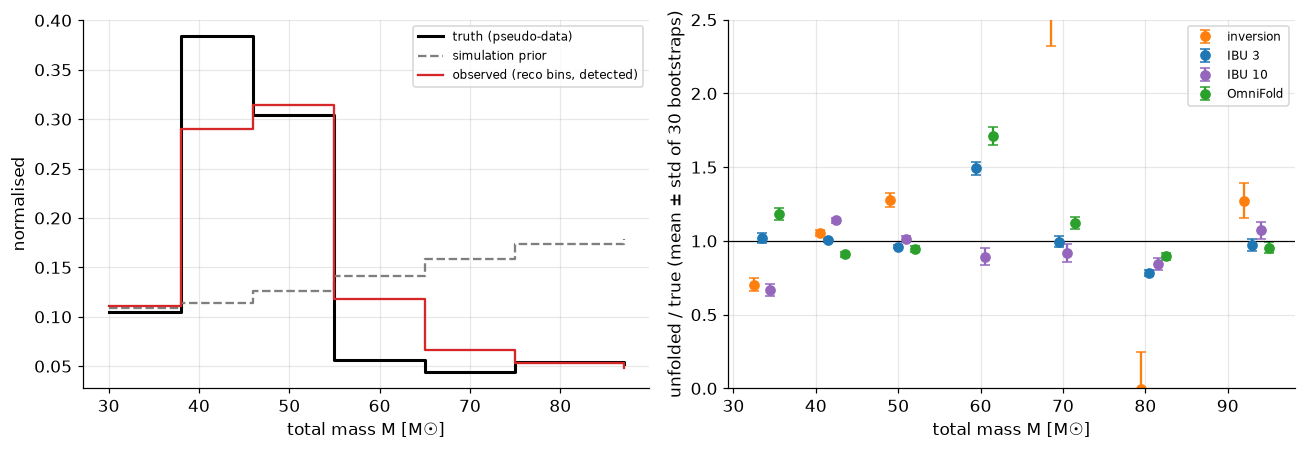

mean |bias|: {'inversion': 0.763, 'IBU 3': 0.115, 'IBU 10': 0.128, 'OmniFold': 0.188} 
mean relative std: {'inversion': 0.154, 'IBU 3': 0.029, 'IBU 10': 0.041, 'OmniFold': 0.034} 
bins with truth within 1 std: {'inversion': 0.0, 'IBU 3': 0.5714285714285714, 'IBU 10': 0.14285714285714285, 'OmniFold': 0.0}


In [6]:
B = 30; rb = np.random.default_rng(5); boots = {k: [] for k in ("inversion", "IBU 3", "IBU 10", "OmniFold")}
idx_pass = np.where(DAT["passed"])[0]
for b in range(B):
    sel = rb.choice(idx_pass, len(idx_pass)); d_b = hist(np.array([EDGES[rbin(m)] + 0.5 for m in DAT["reco"][sel, 0]]))
    boots["inversion"].append(invert(d_b)); boots["IBU 3"].append(ibu(d_b, 3)); boots["IBU 10"].append(ibu(d_b, 10))
    nu = omnifold(SIM, DAT["reco"][sel], iters=4, seed=b); boots["OmniFold"].append(hist(SIM["truth"][:, 0], nu) * (len(sel) / (nu * SIM["passed"]).sum()))
BS = {k: np.array(v) for k, v in boots.items()}
cen = 0.5 * (EDGES[1:] + EDGES[:-1]); fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].step(EDGES[:-1], hist(DAT["truth"][:, 0]) / hist(DAT["truth"][:, 0]).sum(), where="post", color="k", lw=2, label="truth (pseudo-data)")
ax[0].step(EDGES[:-1], hist(SIM["truth"][:, 0]) / hist(SIM["truth"][:, 0]).sum(), where="post", color=g.COLORS["grey"], ls="--", label="simulation prior")
ax[0].step(EDGES[:-1], d_obs / d_obs.sum(), where="post", color=g.COLORS["bayes"], label="observed (reco bins, detected)")
ax[0].set_xlabel("total mass M [M☉]"); ax[0].set_ylabel("normalised"); ax[0].legend(fontsize=8)
for k, c in (("inversion", "C1"), ("IBU 3", "C0"), ("IBU 10", "C4"), ("OmniFold", "C2")):
    m, s = BS[k].mean(0), BS[k].std(0); ax[1].errorbar(cen + {"inversion": -1.5, "IBU 3": -0.5, "IBU 10": 0.5, "OmniFold": 1.5}[k], m / TRUTH, s / TRUTH, fmt="o", color=c, capsize=3, label=k)
ax[1].axhline(1, color="k", lw=.8); ax[1].set_ylim(0, 2.5); ax[1].set_xlabel("total mass M [M☉]"); ax[1].set_ylabel("unfolded / true (mean ± std of 30 bootstraps)"); ax[1].legend(fontsize=8)
fig.tight_layout(); g.savefig(fig, "fig19_unfolding"); plt.show()
bias = {k: float(np.mean(np.abs(BS[k].mean(0) / TRUTH - 1))) for k in BS}; cov = {k: float(np.mean(np.abs(BS[k].mean(0) - TRUTH) < BS[k].std(0))) for k in BS}
sd = {k: float(np.mean(BS[k].std(0) / TRUTH)) for k in BS}; print("mean |bias|:", {k: round(v, 3) for k, v in bias.items()}, "\nmean relative std:", {k: round(v, 3) for k, v in sd.items()}, "\nbins with truth within 1 std:", cov)
g.save_json(dict(edges=EDGES.tolist(), truth=TRUTH.tolist(), observed=d_obs.tolist(), efficiency=EFF.tolist(), table=U.to_dict("records"), omnifold=OF.tolist(), ibu={str(k): v.tolist() for k, v in IBU.items()},
                 inversion=INV.tolist(), mean_abs_bias=bias, mean_rel_std=sd, within_1std=cov), "19_summary.json")

## Output and next step

`results/19_summary.json`, `figures/fig19_unfolding`. Next: prior-mismatch and base-rate studies of the detectors (extensions 58, 59).